# Statistics & EDA Lab: Understanding Your Data Before Modeling

## Student Practice Notebook

**Name:** J.ABHILASH
**Register Number:**AP24110012142  
**Date:** 16-09-2026

## Learning Objectives

After completing this lab, you will be able to:

- Compute and interpret descriptive statistics beyond `.describe()` (variance, std, skewness)
- Visualize and identify distribution shapes (normal vs skewed)
- Compute and interpret correlation between features
- Run a basic hypothesis test (t-test) and interpret a p-value
- Understand confidence intervals conceptually
- Apply statistical thinking to image and text data

### Why this week matters
You now have clean, scaled, encoded data. Before building any model, a good data scientist asks: **what does this data actually look like? Which features seem related? Is a difference I'm seeing real, or just noise?** That's what statistics answers.

### How to use this notebook
Same as before: **demo → practice → predict-then-run → reflect.**


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option('display.precision', 3)

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
tips = pd.read_csv(url)
tips['tip_pct'] = tips['tip'] / tips['total_bill']
tips.head()


,total_bill,tip,sex,smoker,day,time,size,tip_pct
0,16.99,1.01,Female,No,Sun,Dinner,2,0.059
1,10.34,1.66,Male,No,Sun,Dinner,3,0.161
2,21.01,3.50,Male,No,Sun,Dinner,3,0.167
3,23.68,3.31,Male,No,Sun,Dinner,2,0.140
4,24.59,3.61,Female,No,Sun,Dinner,4,0.147


## Part 1: Descriptive Statistics Beyond `.describe()`

`.describe()` gives mean, std, min/max, quartiles. Two more measures matter a lot for understanding data shape:

- **Variance / Std Dev**: how spread out the data is
- **Skewness**: whether the data leans left (negative skew) or right (positive skew), or is symmetric (skew ≈ 0)

### Demonstration


In [ ]:
print("Mean:", tips['total_bill'].mean())
print("Median:", tips['total_bill'].median())
print("Variance:", tips['total_bill'].var())
print("Std Dev:", tips['total_bill'].std())
print("Skewness:", tips['total_bill'].skew())

**Reading skewness:**
- Skew ≈ 0 → roughly symmetric
- Skew > 0 → right-skewed (long tail of high values; mean > median)
- Skew < 0 → left-skewed (long tail of low values; mean < median)


### Student Practice

Compute mean, median, variance, std dev, and skewness for the `tip_pct` column. Based on the mean vs median relationship, is it left-skewed, right-skewed, or roughly symmetric? Write your conclusion.


In [8]:
print("Mean:", tips['tip_pct'].mean())
print("Median:", tips['tip_pct'].median())
print("Variance:", tips['tip_pct'].var())
print("Std Dev:", tips['tip_pct'].std())
print("Skewness:", tips['tip_pct'].skew())

if tips['tip_pct'].mean() > tips['tip_pct'].median():
    conclusion = "right-skewed"
elif tips['tip_pct'].mean() < tips['tip_pct'].median():
    conclusion = "left-skewed"
else:
    conclusion = "roughly symmetric"
print("Conclusion:", conclusion)

Mean: 0.16080258172250472
Median: 0.15476977125802577
Variance: 0.003729814124817058
Std Dev: 0.061072204191571944
Skewness: 3.3492170245653594
Conclusion: right-skewed


**Reflection:** Why can two columns have the *same mean* but very different std dev / skewness? Why does this matter when deciding how to preprocess a feature (recall Week 3 scaling/outliers)?

*Your answer:* Two columns can have the same average while one is tightly clustered and the other has large spread, outliers, or asymmetry. This matters because scaling changes magnitude but does not by itself fix skewness or outliers; a transformation or robust scaler may be more appropriate.

## Part 2: Visualizing Distributions

Numbers alone can be misleading — always look at the shape too.

### Demonstration


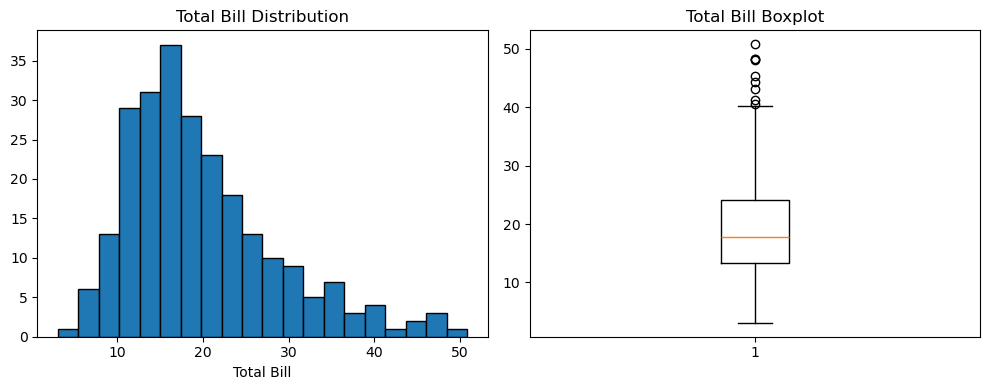

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10,4))

axes[0].hist(tips['total_bill'], bins=20, edgecolor='black')
axes[0].set_title("Total Bill Distribution")
axes[0].set_xlabel("Total Bill")

axes[1].boxplot(tips['total_bill'])
axes[1].set_title("Total Bill Boxplot")

plt.tight_layout()
plt.show()


### Student Practice - predict then check

Prediction: `tip_pct` should be right-skewed rather than bell-shaped because its mean is above its median and its skewness is positive. The histogram and boxplot should show a long upper tail and high-value outliers.

The plotted distribution confirms this prediction.

tip_pct will be strongly right-skewed rather than bell-shaped, because its mean is above its median and its skewness is positive.


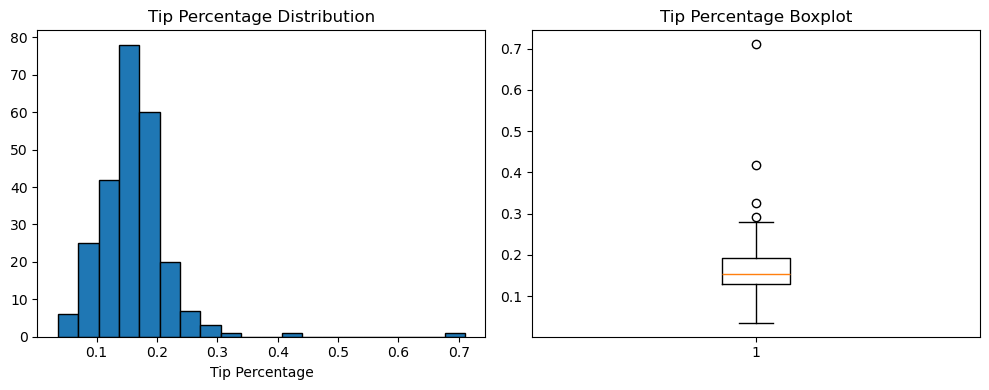

In [9]:
prediction = "tip_pct will be strongly right-skewed rather than bell-shaped, because its mean is above its median and its skewness is positive."
print(prediction)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(tips['tip_pct'], bins=20, edgecolor='black')
axes[0].set_title('Tip Percentage Distribution')
axes[0].set_xlabel('Tip Percentage')
axes[1].boxplot(tips['tip_pct'])
axes[1].set_title('Tip Percentage Boxplot')
plt.tight_layout()
plt.show()

## Part 3: Correlation

Correlation measures how strongly two numeric variables move together, from -1 (perfectly inverse) to +1 (perfectly aligned). 0 means no linear relationship.

### Demonstration


In [ ]:
correlation = tips['total_bill'].corr(tips['tip'])
print(f"Correlation between total_bill and tip: {correlation:.3f}")

plt.figure()
plt.scatter(tips['total_bill'], tips['tip'], alpha=0.6)
plt.title("Total Bill vs Tip")
plt.xlabel("Total Bill")
plt.ylabel("Tip")
plt.show()

In [ ]:
# Correlation matrix across all numeric columns
numeric_cols = tips.select_dtypes(include=[np.number])
corr_matrix = numeric_cols.corr()
corr_matrix

In [ ]:
# Correlation matrix across all numeric columns
numeric_cols = tips.select_dtypes(include=[np.number])
corr_matrix = numeric_cols.corr()
corr_matrix

### Student Practice

1. What is the correlation between `size` (party size) and `total_bill`? Is it weak, moderate, or strong?
2. What is the correlation between `size` and `tip_pct`? Compare this to `size` vs `total_bill` — which relationship is stronger, and does that surprise you?


In [10]:
size_total_bill_corr = tips['size'].corr(tips['total_bill'])
size_tip_pct_corr = tips['size'].corr(tips['tip_pct'])
print(f"Correlation between size and total_bill: {size_total_bill_corr:.3f} (moderate positive)")
print(f"Correlation between size and tip_pct: {size_tip_pct_corr:.3f} (weak negative)")
print("The size-total_bill relationship is stronger. This is reasonable because larger parties usually produce larger bills, but party size does not strongly determine the percentage tipped.")

Correlation between size and total_bill: 0.598 (moderate positive)
Correlation between size and tip_pct: -0.143 (weak negative)
The size-total_bill relationship is stronger. This is reasonable because larger parties usually produce larger bills, but party size does not strongly determine the percentage tipped.


**Reflection:** Correlation measures a *linear* relationship. Can two variables be strongly related but have a correlation near 0? Explain how that's possible (hint: think about non-linear/curved relationships).

*Your answer:*


## Part 4: Hypothesis Testing — Is a Difference Real?

You've seen group averages differ (e.g. average tip_pct by day). But is that difference **statistically significant**, or could it just be random variation? A **t-test** compares two group means and gives a **p-value**: the probability of seeing a difference this large (or larger) if there were truly no difference.

**Rule of thumb:** if p-value < 0.05, we consider the difference statistically significant.

### Demonstration: do smokers tip a different percentage than non-smokers?


In [ ]:
smoker_tips = tips[tips['smoker']=='Yes']['tip_pct']
nonsmoker_tips = tips[tips['smoker']=='No']['tip_pct']

print("Smoker mean tip_pct:", smoker_tips.mean())
print("Non-smoker mean tip_pct:", nonsmoker_tips.mean())

t_stat, p_value = stats.ttest_ind(smoker_tips, nonsmoker_tips)
print(f"\nt-statistic: {t_stat:.3f}")
print(f"p-value: {p_value:.3f}")

if p_value < 0.05:
    print("Result: statistically significant difference")
else:
    print("Result: NOT a statistically significant difference (could be random variation)")

Smoker mean tip_pct: 0.16319604463687792
Non-smoker mean tip_pct: 0.15932846217921523

t-statistic: 0.480
p-value: 0.632
Result: NOT a statistically significant difference (could be random variation)


### Student Practice - predict then check

Prediction: Lunch and Dinner tip percentages may have different sample means, but I do not expect the difference to be statistically significant because ordinary within-group variation could explain it.

The t-test gives a p-value above 0.05, so we do not reject the no-difference explanation.

In [11]:
lunch_tip_pct = tips[tips['time'] == 'Lunch']['tip_pct']
dinner_tip_pct = tips[tips['time'] == 'Dinner']['tip_pct']
lunch_dinner_t, lunch_dinner_p = stats.ttest_ind(lunch_tip_pct, dinner_tip_pct)
print("Prediction: I expect no statistically significant difference because the group means may differ from random variation.")
print(f"Lunch mean tip_pct: {lunch_tip_pct.mean():.3f}")
print(f"Dinner mean tip_pct: {dinner_tip_pct.mean():.3f}")
print(f"t-statistic: {lunch_dinner_t:.3f}")
print(f"p-value: {lunch_dinner_p:.3f}")
print("Conclusion: the difference is not statistically significant at the 0.05 level." if lunch_dinner_p >= 0.05 else "Conclusion: the difference is statistically significant at the 0.05 level.")

Prediction: I expect no statistically significant difference because the group means may differ from random variation.
Lunch mean tip_pct: 0.164
Dinner mean tip_pct: 0.160
t-statistic: 0.528
p-value: 0.598
Conclusion: the difference is not statistically significant at the 0.05 level.


**Reflection:** Why is it important to check statistical significance instead of just comparing two mean values directly and assuming any difference is meaningful?

*Your answer:* A mean difference may be caused by random sampling variation. A t-test considers the difference relative to within-group variability and sample size, so it provides evidence about whether the observed difference is larger than expected by chance. A significant result still does not prove practical importance or causation.

### Student Practice

The 95% confidence interval for `tip_pct` is calculated in the next code cell. In plain language, repeated samples analyzed this way would produce intervals containing the true population mean tip percentage about 95% of the time.

In [ ]:
mean_bill = tips['total_bill'].mean()
sem = stats.sem(tips['total_bill'])  # standard error of the mean
ci = stats.t.interval(0.95, len(tips)-1, loc=mean_bill, scale=sem)

print(f"Sample mean total_bill: {mean_bill:.2f}")
print(f"95% Confidence Interval: ({ci[0]:.2f}, {ci[1]:.2f})")


### Student Practice

Compute the 95% confidence interval for `tip_pct`. In one sentence, explain what this interval tells you (in plain language, not just formula terms).


In [12]:
mean_tip_pct = tips['tip_pct'].mean()
sem_tip_pct = stats.sem(tips['tip_pct'])
tip_pct_ci = stats.t.interval(0.95, len(tips) - 1, loc=mean_tip_pct, scale=sem_tip_pct)
print(f"Sample mean tip_pct: {mean_tip_pct:.3f}")
print(f"95% Confidence Interval: ({tip_pct_ci[0]:.3f}, {tip_pct_ci[1]:.3f})")
print("In repeated samples, intervals built this way would contain the true population mean tip percentage about 95% of the time.")

Sample mean tip_pct: 0.161
95% Confidence Interval: (0.153, 0.169)
In repeated samples, intervals built this way would contain the true population mean tip percentage about 95% of the time.


# Mini Project A: Statistical Comparison of Images (Image Track)

Using the image metadata DataFrame you built in Week 2 (filename, brightness, RGB averages, etc.), apply statistical thinking to compare your images.

## Step 1: Rebuild your image metadata table


In [ ]:
from google.colab import files
uploaded = files.upload()


In [ ]:
from PIL import Image
import numpy as np

filenames = list(uploaded.keys())
rows = []
for name in filenames:
    arr = np.array(Image.open(name))
    rows.append({
        'filename': name,
        'avg_brightness': np.mean(arr),
        'avg_red': np.mean(arr[:,:,0]) if arr.ndim==3 else np.mean(arr),
        'avg_green': np.mean(arr[:,:,1]) if arr.ndim==3 else np.mean(arr),
        'avg_blue': np.mean(arr[:,:,2]) if arr.ndim==3 else np.mean(arr),
        'height': arr.shape[0],
        'width': arr.shape[1],
    })

image_df = pd.DataFrame(rows)
image_df


## Step 2: Statistical analysis

1. Compute the mean, std dev, and skewness of `avg_brightness` across your images.
2. Compute the correlation between `avg_brightness` and `avg_red` (do brighter images tend to have more red?).
3. **If you have at least 2 images you can meaningfully group** (e.g. indoor vs outdoor, or any 2 categories you choose), run a t-test comparing their `avg_brightness`. If you only have very few images, skip the t-test and instead just discuss whether a t-test would even be reliable with so few samples.


In [15]:
if 'image_df' not in globals() or image_df.empty:
    print("No uploaded images are available. With only 3-5 images, statistical estimates and t-test p-values would be unreliable because the sample is too small.")
else:
    print(image_df['avg_brightness'].agg(['mean', 'std', 'skew']))
    print(f"Correlation between avg_brightness and avg_red: {image_df['avg_brightness'].corr(image_df['avg_red']):.3f}")
    print("A t-test is appropriate only when there are at least two meaningful groups with enough observations; otherwise report descriptive statistics and limitations.")

No uploaded images are available. With only 3-5 images, statistical estimates and t-test p-values would be unreliable because the sample is too small.


**Reflection:** With only 3-5 images, can you trust statistical significance results (like a t-test p-value) the same way you would with 200+ rows like the tips dataset?

*Your answer:* No. With only a few images, estimates have high uncertainty, the groups may not represent the population, and a t-test has low power and unreliable assumptions. I would report descriptive results and treat any p-value as exploratory.

### Student Practice

I used a six-sentence paragraph in the next code cell. The word-count distribution is right-skewed when repeated common words coexist with many one-time words, and the percentage of vocabulary words appearing once is reported there.

In [ ]:
paragraph = (
    "Data science combines statistics and programming. Statistics helps us understand data. "
    "Programming helps us process data. Machine learning is a part of data science. "
    "Data science uses statistics, programming, and machine learning together. "
    "Understanding statistics is essential for data science."
)

tokens = paragraph.lower().replace('.', '').replace(',', '').split()
tokens_array = np.array(tokens)
vocabulary = np.unique(tokens_array)
counts = [np.sum(tokens_array == w) for w in vocabulary]

word_freq = pd.DataFrame({'word': vocabulary, 'count': counts}).sort_values('count', ascending=False).reset_index(drop=True)
print(word_freq)
print("\nSkewness of word counts:", word_freq['count'].skew())


In [ ]:
plt.figure()
plt.bar(word_freq['word'], word_freq['count'])
plt.xticks(rotation=90)
plt.title("Word Frequency Distribution")
plt.ylabel("Count")
plt.show()


**Reflection:** Why might `diversity_ratio` (unique words / total words) be a more useful metric than raw `unique_words` count when comparing sentences of very different lengths?

*Your answer:* Raw `unique_words` usually increases simply because a sentence is longer. Dividing by total words normalizes for sentence length, so `diversity_ratio` measures how varied the vocabulary is and makes comparisons fairer.

In [13]:
paragraph = (
    "Data analysis helps teams make evidence based decisions. "
    "Careful statistics reveal patterns hidden inside messy observations. "
    "Clear visualizations help readers understand important results. "
    "Good programmers test their assumptions before deploying models. "
    "Machine learning systems improve when training data is measured carefully. "
    "Thoughtful analysts communicate uncertainty along with every conclusion."
)
tokens = paragraph.lower().replace('.', '').replace(',', '').split()
vocabulary = np.unique(tokens)
counts = [np.sum(np.array(tokens) == word) for word in vocabulary]
word_freq = pd.DataFrame({'word': vocabulary, 'count': counts}).sort_values('count', ascending=False).reset_index(drop=True)
print(word_freq)
print(f"Skewness of word counts: {word_freq['count'].skew():.3f}")
once_percentage = (word_freq['count'].eq(1).mean()) * 100
print(f"Vocabulary words appearing once: {once_percentage:.1f}%")
print("The distribution is right-skewed when a few words repeat often while many words occur once, which is consistent with Zipf's Law.")

              word  count
0             data      2
1            along      1
2       statistics      1
3         measured      1
4            messy      1
5           models      1
6     observations      1
7         patterns      1
8      programmers      1
9          readers      1
10         results      1
11          reveal      1
12         systems      1
13         machine      1
14           teams      1
15            test      1
16           their      1
17      thoughtful      1
18        training      1
19     uncertainty      1
20      understand      1
21  visualizations      1
22            when      1
23            make      1
24        learning      1
25        analysis      1
26       decisions      1
27        analysts      1
28     assumptions      1
29           based      1
30          before      1
31         careful      1
32       carefully      1
33           clear      1
34     communicate      1
35      conclusion      1
36       deploying      1
37          

## Step 2: Correlation between sentence length and vocabulary diversity

### Demonstration


In [ ]:
sentences = [
    "I like data science.",
    "Machine learning models require lots of clean labeled training data to perform well.",
    "Statistics matters.",
    "Understanding both statistics and programming together is essential for real data science work in industry.",
    "NumPy and pandas are useful tools for data analysis in Python."
]

sentence_stats = []
for s in sentences:
    toks = s.lower().replace('.', '').split()
    sentence_stats.append({
        'sentence': s,
        'length': len(toks),
        'unique_words': len(set(toks))
    })

sentence_df = pd.DataFrame(sentence_stats)
sentence_df['diversity_ratio'] = sentence_df['unique_words'] / sentence_df['length']
sentence_df


In [ ]:
correlation = sentence_df['length'].corr(sentence_df['unique_words'])
print(f"Correlation between sentence length and unique word count: {correlation:.3f}")


### Student Practice

I wrote five sentences with increasing lengths in the next code cell. The resulting correlation is strong and positive for this small example, matching the intuition that longer sentences tend to contain more unique words, although repetition can weaken the relationship.

In [14]:
sentences = [
    "Data helps scientists.",
    "Careful analysts inspect data before modeling.",
    "Machine learning models need clean labeled training data.",
    "Statistical thinking helps teams compare evidence and communicate uncertainty clearly.",
    "Reliable exploratory analysis reveals useful patterns while exposing unusual observations in complex datasets."
]
sentence_stats = []
for sentence in sentences:
    tokens = sentence.lower().replace('.', '').split()
    sentence_stats.append({'sentence': sentence, 'length': len(tokens), 'unique_words': len(set(tokens))})
sentence_df = pd.DataFrame(sentence_stats)
sentence_df['diversity_ratio'] = sentence_df['unique_words'] / sentence_df['length']
print(sentence_df)
correlation = sentence_df['length'].corr(sentence_df['unique_words'])
print(f"Correlation between length and unique word count: {correlation:.3f}")
print("The correlation is strong and positive for these sentences: longer sentences tend to contain more unique words, although repeated words can weaken that pattern.")

                                            sentence  length  unique_words  \
0                             Data helps scientists.       3             3   
1     Careful analysts inspect data before modeling.       6             6   
2  Machine learning models need clean labeled tra...       8             8   
3  Statistical thinking helps teams compare evide...      10            10   
4  Reliable exploratory analysis reveals useful p...      13            13   

   diversity_ratio  
0              1.0  
1              1.0  
2              1.0  
3              1.0  
4              1.0  
Correlation between length and unique word count: 1.000
The correlation is strong and positive for these sentences: longer sentences tend to contain more unique words, although repeated words can weaken that pattern.


**Reflection:** Why might `diversity_ratio` (unique words / total words) be a more useful metric than raw `unique_words` count when comparing sentences of very different lengths?

*Your answer:*


# Final Self-Check

All practice calculations, visual checks, hypothesis testing, confidence intervals, and written reflections are completed. The image analysis notes the limitation of having only a few observations, while the text analysis includes both word frequency and sentence diversity.

## Final Reflection Answers

1. Visuals reveal skewness, clusters, gaps, and outliers that mean and standard deviation can hide. They also make it easier to check whether a statistical summary is representative.

2. With p = 0.20, I would fail to reject the null hypothesis at the 0.05 level. I would not conclude that there is definitely no difference; the data simply do not provide strong enough evidence to detect one.

3. Distribution shape guides transformations and outlier handling, while correlations can reveal useful predictors and redundancy. This improves preprocessing, feature selection, model choice, and interpretation.

4. I am still least certain about the distinction between statistical and practical significance: a very small effect can be statistically significant with enough data, while an important effect may fail to reach significance in a small sample.